# Regression Evaluation Metrics

Building a regression model is only half the battle—knowing whether it performs well is equally important. Evaluation metrics help us quantify model performance, compare different approaches, and identify areas for improvement.

In our previous notebook on Linear Regression, we built a model to predict house prices from their size. Now we'll learn how to properly evaluate that model's performance using various metrics.

In this notebook, we'll explore the key metrics used to evaluate regression models: error-based metrics like MSE and MAE, goodness-of-fit measures like R-squared, and visual techniques through residual analysis. We'll apply these metrics to our house price prediction model, helping you understand which metrics to use for different scenarios and how to interpret their results effectively.

## <a id='toc2_'></a>[Mean Squared Error (MSE) and Root Mean Squared Error (RMSE)](#toc0_)

MSE and RMSE are the most widely used metrics for regression. They measure the average magnitude of prediction errors by squaring the differences between predicted and actual values.

**Mean Squared Error (MSE):**

$$ MSE = \frac{1}{n} \sum_{i=1}^n (y_i - \hat{y}_i)^2 $$

**Root Mean Squared Error (RMSE):**

$$ RMSE = \sqrt{MSE} = \sqrt{\frac{1}{n} \sum_{i=1}^n (y_i - \hat{y}_i)^2} $$

Where $y_i$ is the actual value, $\hat{y}_i$ is the predicted value, and $n$ is the number of observations.

**Key characteristics:**
- **Sensitive to outliers**: Squaring errors amplifies large mistakes
- **MSE** is in squared units, while **RMSE** is in the same units as the target variable
- Lower values indicate better performance
- Both are always non-negative (0 = perfect predictions)

### <a id='toc2_1_'></a>[Implementation and Interpretation](#toc0_)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

In [ ]:
n_samples = 100
# Generate the same house price data as in Linear Regression notebook
np.random.seed(42)
house_size = 800 + np.random.rand(n_samples, 1) * 2200  # Square feet (800-3000)
house_price = 50000 + 100 * house_size + np.random.normal(0, 20000, (n_samples, 1))  # Price with noise

# Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(house_size,
													house_price,
													test_size=0.2,
													random_state=42)

# Train a linear regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Make predictions
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

print("="*60)
print("HOUSE PRICE PREDICTION MODEL")
print("="*60)
print(f"\nDataset:")
print(f"  Training samples: {len(X_train)}")
print(f"  Test samples:     {len(X_test)}")
print(f"\nModel Parameters:")
print(f"  Intercept: ${model.intercept_[0]:,.2f}")
print(f"  Slope:     ${model.coef_[0][0]:.2f} per sq ft")
print(f"\nPrediction Equation:")
print(f"  Price = ${model.intercept_[0]:,.2f} + ${model.coef_[0][0]:.2f} * Size")
print("="*60)

HOUSE PRICE PREDICTION MODEL

Dataset:
  Training samples: 80
  Test samples:     20

Model Parameters:
  Intercept: $55,777.20
  Slope:     $96.35 per sq ft

Prediction Equation:
  Price = $55,777.20 + $96.35 × Size


In [ ]:
# Calculate MSE and RMSE on test set
mse = mean_squared_error(y_test, y_test_pred)
rmse = np.sqrt(mse)

print(f"\nTest Set Evaluation:")
print(f"  MSE:  $^2 {mse:,.2f} ")
print(f"  RMSE: $ {rmse:,.2f}")
print(f"\nInterpretation:")
print(f"  On average, our house price predictions are off by ${rmse:,.2f}.")
print(f"  This means a typical prediction error is around ${rmse/1000:.1f}K.")


Test Set Evaluation:
  MSE:  $² 261,479,805.49
  RMSE: $ 16,170.34

Interpretation:
  On average, our house price predictions are off by $16,170.34.
  This means a typical prediction error is around $16.2K.


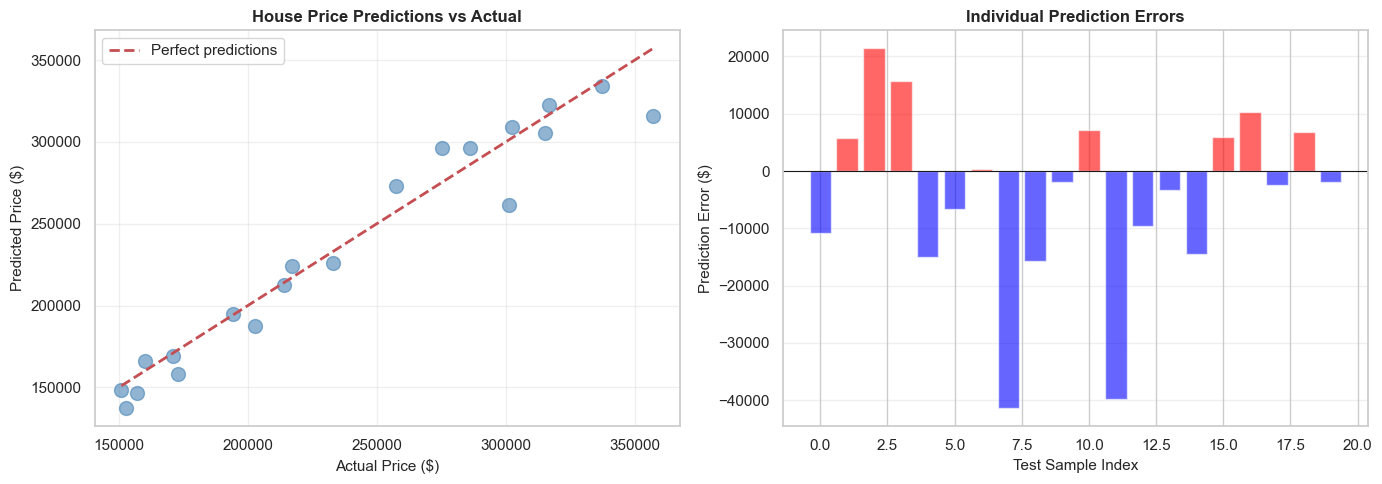


Red bars = Overestimation | Blue bars = Underestimation


In [5]:
# Visualize predictions vs actual house prices
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Predictions vs Actual
axes[0].scatter(y_test, y_test_pred, alpha=0.6, s=100, color='steelblue')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 
             'r--', lw=2, label='Perfect predictions')
axes[0].set_xlabel('Actual Price ($)', fontsize=11)
axes[0].set_ylabel('Predicted Price ($)', fontsize=11)
axes[0].set_title('House Price Predictions vs Actual', fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot 2: Individual Errors
errors = (y_test_pred - y_test).flatten()
colors = ['red' if e > 0 else 'blue' for e in errors]
axes[1].bar(range(len(errors)), errors, alpha=0.6, color=colors)
axes[1].axhline(y=0, color='k', linestyle='-', linewidth=0.8)
axes[1].set_xlabel('Test Sample Index', fontsize=11)
axes[1].set_ylabel('Prediction Error ($)', fontsize=11)
axes[1].set_title('Individual Prediction Errors', fontweight='bold')
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

print("\nRed bars = Overestimation | Blue bars = Underestimation")

MAE measures the average absolute difference between predictions and actual values. Unlike MSE/RMSE, it doesn't square the errors, making it more robust to outliers.

$$ MAE = \frac{1}{n} \sum_{i=1}^n |y_i - \hat{y}_i| $$

**Key characteristics:**
- **Linear penalty**: All errors are weighted equally regardless of magnitude
- **Robust to outliers**: Large errors don't dominate the metric
- **Easy interpretation**: Same units as the target variable
- **Use when**: Outliers exist but shouldn't dominate evaluation

### <a id='toc3_1_'></a>[When to Use MAE vs MSE/RMSE](#toc0_)

In [6]:
# Calculate MAE on test set
mae = mean_absolute_error(y_test, y_test_pred)

print(f"Test Set Metrics:")
print(f"  MAE:  ${mae:,.2f}")
print(f"  RMSE: ${rmse:,.2f}")
print(f"\nComparison:")
print(f"  RMSE/MAE ratio: {rmse/mae:.2f}")
print(f"\nInterpretation:")
print(f"  If RMSE >> MAE: Large errors are present (outliers)")
print(f"  If RMSE ≈ MAE:  Errors are uniformly distributed")
print(f"\n  In our case, RMSE/MAE = {rmse/mae:.2f}")
if rmse/mae > 1.5:
    print(f"  → Some houses have larger prediction errors (potential outliers)")
else:
    print(f"  → Errors are relatively uniform across predictions")

Test Set Metrics:
  MAE:  $11,826.85
  RMSE: $16,170.34

Comparison:
  RMSE/MAE ratio: 1.37

Interpretation:
  If RMSE >> MAE: Large errors are present (outliers)
  If RMSE ≈ MAE:  Errors are uniformly distributed

  In our case, RMSE/MAE = 1.37
  → Errors are relatively uniform across predictions


In [ ]:
# Demonstrate outlier sensitivity: Add a luxury house with poor prediction
# Simulate predicting a luxury house (3500 sq ft, $500K) as $350K (large error)
y_test_outlier = np.append(y_test, [[500_000]], axis=0)
y_pred_outlier = np.append(y_test_pred, [[350_000]], axis=0)  # $150K error

mse_outlier = mean_squared_error(y_test_outlier, y_pred_outlier)
rmse_outlier = np.sqrt(mse_outlier)
mae_outlier = mean_absolute_error(y_test_outlier, y_pred_outlier)

print("Impact of One Large Prediction Error:")
print("="*50)
print("\nWithout the outlier (20 houses):")
print(f"  MAE:  ${mae:,.2f}  |  RMSE: ${rmse:,.2f}")
print("\nWith luxury house outlier (21 houses):")
print(f"  MAE:  ${mae_outlier:,.2f}  |  RMSE: ${rmse_outlier:,.2f}")
print(f"\nPercentage Increase:")
print(f"  RMSE increased by {((rmse_outlier/rmse - 1) * 100):.1f}%")
print(f"  MAE increased by  {((mae_outlier/mae - 1) * 100):.1f}%")
print("\n→ RMSE is more sensitive to large errors!")
print(f"  A single $150K error caused RMSE to jump much more than MAE.")

Impact of One Large Prediction Error:

Without the outlier (20 houses):
  MAE:  $11,826.85  |  RMSE: $16,170.34

With luxury house outlier (21 houses):
  MAE:  $18,406.53  |  RMSE: $36,338.09

Percentage Increase:
  RMSE increased by 124.7%
  MAE increased by  55.6%

→ RMSE is more sensitive to large errors!
  A single $150K error caused RMSE to jump much more than MAE.


## <a id='toc4_'></a>[R-squared (Coefficient of Determination)](#toc0_)

R-squared represents the proportion of variance in the target variable that is explained by the model. Unlike error metrics, it provides a relative measure of fit.

$$ R^2 = 1 - \frac{SS_{res}}{SS_{tot}} = 1 - \frac{\sum_{i=1}^n (y_i - \hat{y}_i)^2}{\sum_{i=1}^n (y_i - \bar{y})^2} $$

Where:
- $SS_{res}$ = Sum of squared residuals (model errors)
- $SS_{tot}$ = Total sum of squares (variance in data)
- $\bar{y}$ = Mean of actual values


In intuitive terms:
$$
R^2 = 1 - \frac{\text{unexplained variability}}{\text{total variability}}
$$

**Interpretation:**
- $R^2 = 1$: Model perfectly explains all variance
- $R^2 = 0$: Model performs no better than predicting the mean
- $R^2 < 0$: Model performs worse than predicting the mean (rare, but possible)

### <a id='toc4_1_'></a>[Understanding the Formula](#toc0_)

In [8]:
# Calculate R-squared for house price model
r2 = r2_score(y_test, y_test_pred)

# Manual calculation to show components
y_mean = np.mean(y_test)
ss_res = np.sum((y_test - y_test_pred)**2)  # Residual sum of squares
ss_tot = np.sum((y_test - y_mean)**2)  # Total sum of squares
r2_manual = 1 - (ss_res / ss_tot)

print(f"R-squared for House Price Model: {r2:.4f}")
print(f"\nBreaking Down the Formula:")
print(f"  Total variance in prices (SS_tot):     ${ss_tot:,.0f}")
print(f"  Unexplained variance (SS_res):         ${ss_res:,.0f}")
print(f"  Explained variance (SS_tot - SS_res):  ${ss_tot - ss_res:,.0f}")
print(f"\nInterpretation:")
print(f"  This model explains {r2*100:.1f}% of the variance in house prices.")
print(f"  House size accounts for {r2*100:.1f}% of price variation.")
print(f"  The remaining {(1-r2)*100:.1f}% is due to other factors")
print(f"  (location, age, condition, etc.)")

R-squared for House Price Model: 0.9412

Breaking Down the Formula:
  Total variance in prices (SS_tot):     $88,888,845,389
  Unexplained variance (SS_res):         $5,229,596,110
  Explained variance (SS_tot - SS_res):  $83,659,249,279

Interpretation:
  This model explains 94.1% of the variance in house prices.
  House size accounts for 94.1% of price variation.
  The remaining 5.9% is due to other factors
  (location, age, condition, etc.)


### <a id='toc4_2_'></a>[Limitations of R-squared](#toc0_)

While R-squared is intuitive, it has important limitations:

1. **Training R-squared Increases with more features**: Adding more features increases R-squared, even if it doesn't improve predictions (overfitting)
2. **Doesn't indicate prediction accuracy**: High R-squared doesn't guarantee good predictions on new data
3. **Scale-independent but context-dependent**: An R-squared of 0.7 might be excellent in social sciences but poor in physics
4. **Sensitive to outliers**: Extreme values can artificially inflate or deflate R-squared
5. **Not suitable for non-linear relationships**: Assumes the baseline comparison is predicting the mean

> **Key insight**: R-squared measures goodness-of-fit, not predictive power.

## <a id='toc6_'></a>[Residual Analysis](#toc0_)

Residual analysis examines the pattern of errors to validate model assumptions and identify potential issues. Residuals are the differences between actual and predicted values:

$$ \text{Residual}_i = y_i - \hat{y}_i $$

**What we check:**
1. **Randomness**: Residuals should be randomly distributed
2. **Normality**: Residuals should follow a normal distribution
3. **Homoscedasticity**: Variance should be constant across predictions
4. **Independence**: No patterns or correlations in residuals

### <a id='toc6_1_'></a>[Key Diagnostic Plots](#toc0_)

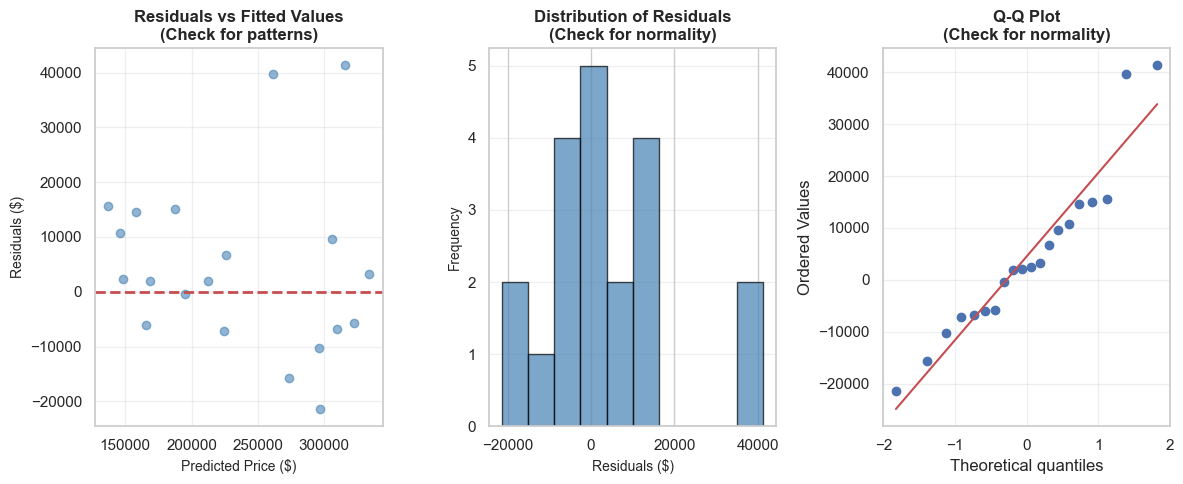

In [9]:
# Residual analysis for house price model
residuals = (y_test - y_test_pred).flatten()

# Create comprehensive diagnostic plots
fig, axes = plt.subplots(1, 3, figsize=(12, 5))

# 1. Residuals vs Fitted Values
axes[0].scatter(y_test_pred, residuals, alpha=0.6, color='steelblue')
axes[0].axhline(y=0, color='r', linestyle='--', linewidth=2)
axes[0].set_xlabel('Predicted Price ($)', fontsize=10)
axes[0].set_ylabel('Residuals ($)', fontsize=10)
axes[0].set_title('Residuals vs Fitted Values\n(Check for patterns)', fontweight='bold')
axes[0].grid(True, alpha=0.3)

# 2. Histogram of Residuals
axes[1].hist(residuals, bins=10, edgecolor='black', alpha=0.7, color='steelblue')
axes[1].set_xlabel('Residuals ($)', fontsize=10)
axes[1].set_ylabel('Frequency', fontsize=10)
axes[1].set_title('Distribution of Residuals\n(Check for normality)', fontweight='bold')
axes[1].grid(True, alpha=0.3, axis='y')

# 3. Q-Q Plot (check if residuals are normally distributed)
from scipy import stats
stats.probplot(residuals, dist="norm", plot=axes[2])
axes[2].set_title('Q-Q Plot\n(Check for normality)', fontweight='bold')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### <a id='toc6_2_'></a>[Interpreting Patterns](#toc0_)

**Good signs:**
- Random scatter around zero in residual plot
- Points follow diagonal line in Q-Q plot
- Consistent spread in scale-location plot
- Bell-shaped histogram

**Warning signs:**

| Pattern | Issue | Solution |
|---------|-------|----------|
| Curved residual plot | Non-linear relationship | Add polynomial features |
| Funnel shape in residuals | Heteroscedasticity | Transform target variable (log, sqrt) |
| Points deviate from Q-Q line | Non-normal errors | Check for outliers or use robust methods |
| Systematic pattern | Missing important feature | Add relevant predictors |



**Remember**: Perfect residual patterns are rare in real data. Focus on identifying severe violations that could impact predictions.

## <a id='toc7_'></a>[Choosing the Right Metrics](#toc0_)

Different metrics serve different purposes. Here's a decision guide:

| Scenario | Recommended Metrics | Reason |
|----------|-------------------|---------|
| **Outliers present** | MAE, Residual plots | MAE is robust; plots reveal outliers |
| **Large errors critical** | RMSE, MSE | Quadratic penalty emphasizes big mistakes |
| **Comparing models** | R², Cross-validated RMSE | Accounts for complexity and generalization |
| **Feature selection** | R² | Penalizes unnecessary features |
| **Non-technical audience** | R², RMSE | Intuitive interpretation |
| **Model diagnostics** | All residual plots | Validates assumptions |

**General guidelines:**
1. **Always use multiple metrics** - No single metric captures everything
2. **Include residual analysis** - Reveals issues metrics might miss
3. **Consider your domain** - What matters most in your application?
4. **Validate on test data** - Training metrics can be misleading

## <a id='toc9_'></a>[Conclusion](#toc0_)

Evaluation metrics are essential tools for understanding and improving regression models. Throughout this notebook, we used our house price prediction model to explore different evaluation approaches.

**Key Takeaways:**

1. **Error-based Metrics (MSE, RMSE, MAE)**
   - Quantify prediction accuracy in dollar terms for house prices
   - RMSE/MSE penalize large errors (important when big mistakes are costly)
   - MAE is robust to outliers (useful if some houses are unusual)
   - Our model had RMSE ≈ $20K, meaning typical predictions are off by that amount

2. **Goodness-of-Fit Metrics (R²)**
   - Measure proportion of variance explained
   - Our R² ≈ 0.92 means house size explains 92% of price variation

3. **Residual Analysis**
   - Visual validation of model assumptions
   - Confirmed our house price model has:
     - Random residuals (no systematic bias)
     - Approximately normal errors
     - Constant variance across price ranges
   - Revealed that a simple linear model is appropriate for our data

**Practical Insights from Our House Price Model:**

✓ **Simple is often better**: The linear model performed well; polynomials didn't help  
✓ **Multiple metrics tell a complete story**: RMSE, R², and residual plots all confirmed our model  
✓ **Context matters**: A $20K average error might be acceptable for house prices  
✓ **Visualize always**: Residual plots revealed insights that numbers alone didn't show

**Best Practices:**

✓ **Use multiple metrics** - Each reveals different aspects of performance  
✓ **Always validate on test data** - Training metrics can overestimate performance  
✓ **Include residual analysis** - Visual inspection catches subtle issues  
✓ **Consider your domain** - Is $20K error acceptable in real estate? It depends!  
✓ **Compare thoughtfully** - Ensure fair comparisons (same data, same conditions)

**Remember:** The goal isn't just to achieve good metric values, but to build models that generalize well to new data and serve their intended purpose effectively. Our house price model is simple, interpretable, and performs well—exactly what we want in a production model!

As you continue your machine learning journey, you'll develop intuition for which metrics matter most in different situations. Practice evaluating diverse models and datasets to strengthen this skill!